# Проект. Яндекс.Афиша

Хромов Денис. 15.09.2026

# Введение

Коллеги из продуктовой команды просят провести исследовательский анализ данных в Python, чтобы выявить инсайты об изменении пользовательских предпочтений и популярности событий осенью 2024 года, а также проверить гипотезы о разнице в поведении пользователей с мобильными и стационарными устройствами.



Цель: Подготовить датасет к работе, исследовать динамику и структуру финансирования стартапов и ответить на вопросы, важные для оценки инвестиционных стратегий.

Задачи:

1) `Загрузить и подготовить данные.`
Анализ и подготовка данных для дальнейшего исследования, включая проверку на пропуски, дубликаты, преобразование валют и создание новых столбцов, таких как выручка в рублях, выручка с одного билета и информация о сезонности.

2) `Провести исследовательский анализ данных.`
Изучение распределения заказов по различным сегментам (тип мероприятия, тип устройства, категории по возрастному рейтингу) и анализ их сезонных изменений. Включает расчет средней выручки с одного билета, а также сравнение активности пользователей.

3) `Проанализировать активность пользователей в 2024 году.`
Анализ динамики заказов, количества активных пользователей (DAU), средней активности пользователей и выявление недельной цикличности.
Определение наиболее популярных мероприятий, анализ выручки по регионам и партнерам, а также выявление лидеров по количеству мероприятий и заказов.

4) `Проверить гипотезы.`
Статистический анализ для проверки гипотез о более высокой активности пользователей мобильных приложений по сравнению с десктопными, включая использование соответствующих статистических тестов.

5) `Сформулировать общий вывод и рекомендации.`
Описание основных результатов исследования, анализ трендов, выявление лидеров среди регионов и партнеров, а также предложения по улучшению пользовательского опыта и дальнейшему развитию сервиса.

##  Знакомство с данными: загрузка и предобработка

Датасет `final_tickets_orders_df` включает информацию обо всех заказах билетов, совершённых с двух типов устройств - мобильных и стационарных. Поля датасета:

* `order_id` - уникальный идентификатор заказа.
* `user_id` - уникальный идентификатор пользователя.
* `created_dt_msk` - дата создания заказа (московское время).
* `created_ts_msk` - дата и время создания заказа (московское время).
* `event_id` - идентификатор мероприятия из таблицы events.
* `cinema_circuit` - сеть кинотеатров. Если не применимо, то здесь будет значение 'нет'.
* `age_limit` - возрастное ограничение мероприятия.
* `currency_code` - валюта оплаты, например rub для российских рублей.
* `device_type_canonical` - тип устройства, с которого был оформлен заказ, например mobile для мобильных устройств, desktop для стационарных.
* `revenue` - выручка от заказа.
* `service_name` - название билетного оператора.
* `tickets_count` - количество купленных билетов.
* `total` - общая сумма заказа.
* `days_since_prev` - количество дней с предыдущей покупки для каждого пользователя. Если покупки не было, то данные содержат пропуск.  

Второй датасет `final_tickets_events_df` содержит информацию о событиях, включая город и регион события, а также информацию о площадке проведения мероприятия. Датасет содержит такие поля:

* `event_id` - уникальный идентификатор мероприятия.
* `event_name` - название мероприятия. Аналог поля event_name_code из исходной базы данных.
* `event_type_description` - описание типа мероприятия.
* `event_type_main` — основной тип мероприятия: театральная постановка, концерт и так далее.
* `organizers` - организаторы мероприятия.
* `region_name` - название региона.
* `city_name` - название города.
* `venue_id` - уникальный идентификатор площадки.
* `venue_name` - название площадки.
* `venue_address` - адрес площадки.

Выручка от заказов представлена в двух валютах - российских рублях и казахстанских тенге. Для удобства решения было бы корректно привести данные к одной валюте, например к российским рублям. Для этого будем использовать датасет `final_tickets_tenge_df` с информацией о курсе тенге к российскому рублю за 2024 год. Значения в рублях представлено для 100 тенге. Датасет содержит такие поля:

* `nominal` - номинал (100 тенге).
* `data` - дата.
* `curs` - курс тенге к рублю.
* `cdx` - обозначение валюты (kzt).

Загрузим датафреймы и осмотрим данные:

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats

In [2]:
df_orders = pd.read_csv("https://code.s3.yandex.net/datasets/final_tickets_orders_df.csv")
df_events = pd.read_csv("https://code.s3.yandex.net/datasets/final_tickets_events_df.csv")
df_tenge = pd.read_csv("https://code.s3.yandex.net/datasets/final_tickets_tenge_df.csv")

In [3]:
df_orders.head()

,order_id,user_id,created_dt_msk,created_ts_msk,event_id,cinema_circuit,age_limit,currency_code,device_type_canonical,revenue,service_name,tickets_count,total,days_since_prev
0,4359165,0002849b70a3ce2,2024-08-20,2024-08-20 16:08:03,169230,нет,16,rub,mobile,1521.94,Край билетов,4,10870.99,NaN
1,7965605,0005ca5e93f2cf4,2024-07-23,2024-07-23 18:36:24,237325,нет,0,rub,mobile,289.45,Мой билет,2,2067.51,NaN
2,7292370,0005ca5e93f2cf4,2024-10-06,2024-10-06 13:56:02,578454,нет,0,rub,mobile,1258.57,За билетом!,4,13984.16,75.0
3,1139875,000898990054619,2024-07-13,2024-07-13 19:40:48,387271,нет,0,rub,mobile,8.49,Лови билет!,2,212.28,NaN
4,972400,000898990054619,2024-10-04,2024-10-04 22:33:15,509453,нет,18,rub,mobile,1390.41,Билеты без проблем,3,10695.43,83.0


In [4]:
df_events.head()

,event_id,event_name,event_type_description,event_type_main,organizers,region_name,city_name,city_id,venue_id,venue_name,venue_address
0,4436,e4f26fba-da77-4c61-928a-6c3e434d793f,спектакль,театр,№4893,Североярская область,Озёрск,2,1600,"Кладбище искусств ""Проблема"" и партнеры","наб. Загородная, д. 785"
1,5785,5cc08a60-fdea-4186-9bb2-bffc3603fb77,спектакль,театр,№1931,Светополянский округ,Глиноград,54,2196,"Лекции по искусству ""Свет"" Групп","ул. Ягодная, д. 942"
2,8817,8e379a89-3a10-4811-ba06-ec22ebebe989,спектакль,театр,№4896,Североярская область,Озёрск,2,4043,"Кинокомитет ""Золотая"" Инк","ш. Коммуны, д. 92 стр. 6"
3,8849,682e3129-6a32-4952-9d8a-ef7f60d4c247,спектакль,театр,№4960,Каменевский регион,Глиногорск,213,1987,"Выставка ремесел ""Свет"" Лтд","пер. Набережный, д. 35"
4,8850,d6e99176-c77f-4af0-9222-07c571f6c624,спектакль,театр,№4770,Лесодальний край,Родниковец,55,4230,"Фестивальный проект ""Листья"" Групп","пер. Проезжий, д. 9"


In [5]:
df_tenge.head()

,data,nominal,curs,cdx
0,2024-01-10,100,19.9391,kzt
1,2024-01-11,100,19.7255,kzt
2,2024-01-12,100,19.5839,kzt
3,2024-01-13,100,19.4501,kzt
4,2024-01-14,100,19.4501,kzt


In [6]:
df_orders.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 290849 entries, 0 to 290848
Data columns (total 14 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   order_id               290849 non-null  int64  
 1   user_id                290849 non-null  object 
 2   created_dt_msk         290849 non-null  object 
 3   created_ts_msk         290849 non-null  object 
 4   event_id               290849 non-null  int64  
 5   cinema_circuit         290849 non-null  object 
 6   age_limit              290849 non-null  int64  
 7   currency_code          290849 non-null  object 
 8   device_type_canonical  290849 non-null  object 
 9   revenue                290849 non-null  float64
 10  service_name           290849 non-null  object 
 11  tickets_count          290849 non-null  int64  
 12  total                  290849 non-null  float64
 13  days_since_prev        268909 non-null  float64
dtypes: float64(3), int64(4), object(7)
m

В датафрейме `df_orders`: 
* имеются пропуски в новом столбце `days_since_prev`, которым дано объяснение - в этих строках не совершалось покупок, значит оставим их как есть
* неправильно определены типы данных в `created_dt_msk` и `created_ts_msk`. 

In [7]:
df_events.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 22427 entries, 0 to 22426
Data columns (total 11 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   event_id                22427 non-null  int64 
 1   event_name              22427 non-null  object
 2   event_type_description  22427 non-null  object
 3   event_type_main         22427 non-null  object
 4   organizers              22427 non-null  object
 5   region_name             22427 non-null  object
 6   city_name               22427 non-null  object
 7   city_id                 22427 non-null  int64 
 8   venue_id                22427 non-null  int64 
 9   venue_name              22427 non-null  object
 10  venue_address           22427 non-null  object
dtypes: int64(3), object(8)
memory usage: 1.9+ MB


Датафрейм `df_events`: 
* не содержит пропусков
* типы данных определены верно

In [8]:
df_tenge.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 357 entries, 0 to 356
Data columns (total 4 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   data     357 non-null    object 
 1   nominal  357 non-null    int64  
 2   curs     357 non-null    float64
 3   cdx      357 non-null    object 
dtypes: float64(1), int64(1), object(2)
memory usage: 11.3+ KB


Датафрейм `df_tenge`:  
* не содержит пропусков
* нужно изменить тип данных столбца `data` на тип date

### Промежуточный вывод 
* Привести `created_dt_msk` и `created_ts_msk` из `df_orders`, а также `data` из `df_tenge`  к формату даты.
* Привести выручку к единой валюте (rub).
* Объединить датафреймы в один массив

## Предобработка данных

### Проведем изменение типов данных

In [9]:
df_orders['created_dt_msk'] = pd.to_datetime(df_orders['created_dt_msk']).dt.normalize()
df_orders['created_ts_msk'] = pd.to_datetime(df_orders['created_ts_msk'])
df_tenge['data'] = pd.to_datetime(df_tenge['data']).dt.normalize()

In [10]:
# Проверим преобразование
df_orders.dtypes

order_id                          int64
user_id                          object
created_dt_msk           datetime64[ns]
created_ts_msk           datetime64[ns]
event_id                          int64
cinema_circuit                   object
age_limit                         int64
currency_code                    object
device_type_canonical            object
revenue                         float64
service_name                     object
tickets_count                     int64
total                           float64
days_since_prev                 float64
dtype: object

In [11]:
df_tenge.dtypes

data       datetime64[ns]
nominal             int64
curs              float64
cdx                object
dtype: object

### Проверка на дубликаты

Сперва убедимся что ключи для объединения не содержат дубликатов

In [12]:
df_events['event_id'].duplicated().sum()

0

In [13]:
df_tenge['data'].duplicated().sum()

0

Проверим датафреймы на наличие явных дубликатов

In [14]:
print(df_orders.duplicated().sum())
print(df_events.duplicated().sum())
print(df_tenge.duplicated().sum())

0
0
0


Переходим к проверке неявных дубликатов:  
* Сперва проверим по одинаковому id, но с разным содержанием строк
* Затем по разным id с одинаковым содержанием в том числе по времени с точностью до секунды (что может быть вызвано сбоем в работе сайта)
* Переберем категориальные переменные

In [15]:
# 1 шаг
print(df_orders['order_id'].duplicated().sum())

print(df_events['event_id'].duplicated().sum())

0
0


In [16]:
# 2 шаг
duplicates = df_orders.groupby(
    ['user_id', 'event_id', 'created_ts_msk', 'tickets_count', 'revenue']
).size()

duplicates = duplicates[duplicates > 1]

print(len(duplicates))


41


In [17]:
# Удалим эти дубликаты
df_orders = df_orders.drop_duplicates(
    subset=['user_id', 'event_id', 'created_ts_msk', 'tickets_count', 'revenue'],
    keep='first'
)

In [18]:
# 3 шаг
for col in ['cinema_circuit', 'age_limit', 'currency_code',
            'device_type_canonical', 'service_name']:
    print(f'{col}:\n', df_orders[col].unique())

cinema_circuit:
 ['нет' 'Другое' 'Киномакс' 'КиноСити' 'Москино' 'ЦентрФильм']
age_limit:
 [16  0 18 12  6]
currency_code:
 ['rub' 'kzt']
device_type_canonical:
 ['mobile' 'desktop']
service_name:
 ['Край билетов' 'Мой билет' 'За билетом!' 'Лови билет!'
 'Билеты без проблем' 'Облачко' 'Лучшие билеты' 'Прачечная' 'Быстробилет'
 'Дом культуры' 'Весь в билетах' 'Билеты в руки' 'Тебе билет!'
 'Show_ticket' 'Городской дом культуры' 'Яблоко' 'Билет по телефону'
 'Выступления.ру' 'Росбилет' 'Шоу начинается!' 'Мир касс' 'Восьмёрка'
 'Телебилет' 'Crazy ticket!' 'Реестр' 'Быстрый кассир' 'КарандашРУ'
 'Радио ticket' 'Дырокол' 'Вперёд!' 'Кино билет' 'Цвет и билет' 'Зе Бест!'
 'Тех билет' 'Лимоны' 'Билеты в интернете']


In [19]:
for col in ['event_type_main', 'region_name']:
    print(f'{col}:\n', df_events[col].unique())

event_type_main:
 ['театр' 'концерты' 'ёлки' 'другое' 'стендап' 'выставки' 'спорт']
region_name:
 ['Североярская область' 'Светополянский округ' 'Каменевский регион'
 'Лесодальний край' 'Медовская область' 'Широковская область'
 'Тепляковская область' 'Травяная область' 'Зоринский регион'
 'Серебринская область' 'Яблоневская область' 'Глиногорская область'
 'Речиновская область' 'Озернинский край' 'Горицветская область'
 'Солнечнореченская область' 'Травиницкий округ' 'Солнечноземская область'
 'Ключеводский округ' 'Островная область' 'Луговая область'
 'Каменноозёрный край' 'Лесостепной край' 'Зеленоградский округ'
 'Поленовский край' 'Лугоградская область' 'Синегорский регион'
 'Малиновая область' 'Речицкая область' 'Дальнеземская область'
 'Заречная область' 'Североозёрский округ' 'Дальнезорский край'
 'Малиновоярский округ' 'Сосновская область' 'Златопольский округ'
 'Ягодиновская область' 'Берестовский округ' 'Золотоключевской край'
 'Каменноярский край' 'Голубевский округ' 'Боров

Неявные дубликаты отсутствуют. После предобработки неявных дубликатов мы удалили 41 строку

### Объединение датафреймов

In [20]:

df_step1 = df_orders.merge(df_events, on='event_id', how='inner')

df = df_step1.merge(
    df_tenge[['data', 'nominal', 'curs']],
    left_on='created_dt_msk',
    right_on='data',
    how='left'
)

df = df.drop('data', axis=1)

Проверим появились ли пропуски в объединенном датафрейме

In [21]:
(df.isna().mean() * 100).sort_values(ascending=False)

days_since_prev           7.541462
user_id                   0.000000
nominal                   0.000000
venue_address             0.000000
venue_name                0.000000
venue_id                  0.000000
city_id                   0.000000
city_name                 0.000000
region_name               0.000000
organizers                0.000000
event_type_main           0.000000
event_type_description    0.000000
event_name                0.000000
order_id                  0.000000
total                     0.000000
tickets_count             0.000000
service_name              0.000000
revenue                   0.000000
device_type_canonical     0.000000
currency_code             0.000000
age_limit                 0.000000
cinema_circuit            0.000000
event_id                  0.000000
created_ts_msk            0.000000
created_dt_msk            0.000000
curs                      0.000000
dtype: float64

Пропуски в `days_since_prev` остались без изменений - их мы не трогаем.
Однако в 10 колонках с информацией о мероприятиях появились пропуски, составляющие 0.08 от всего объема. Их можно удалить

In [22]:
df = df.dropna(subset=['event_type_main', 'region_name', 'city_name', 'venue_name'])

In [23]:
(df.isna().mean() * 100).sort_values(ascending=False)

days_since_prev           7.541462
user_id                   0.000000
nominal                   0.000000
venue_address             0.000000
venue_name                0.000000
venue_id                  0.000000
city_id                   0.000000
city_name                 0.000000
region_name               0.000000
organizers                0.000000
event_type_main           0.000000
event_type_description    0.000000
event_name                0.000000
order_id                  0.000000
total                     0.000000
tickets_count             0.000000
service_name              0.000000
revenue                   0.000000
device_type_canonical     0.000000
currency_code             0.000000
age_limit                 0.000000
cinema_circuit            0.000000
event_id                  0.000000
created_ts_msk            0.000000
created_dt_msk            0.000000
curs                      0.000000
dtype: float64

### Работа с выбросами

In [24]:
df.groupby('currency_code')['revenue'].describe()

,count,mean,std,min,25%,50%,75%,max
currency_code,,,,,,,,
kzt,5068.0,4995.827484,4917.039292,0.00,518.100,3698.83,7397.66,26425.86
rub,285499.0,548.032790,871.784009,-90.76,114.215,346.70,793.32,81174.54


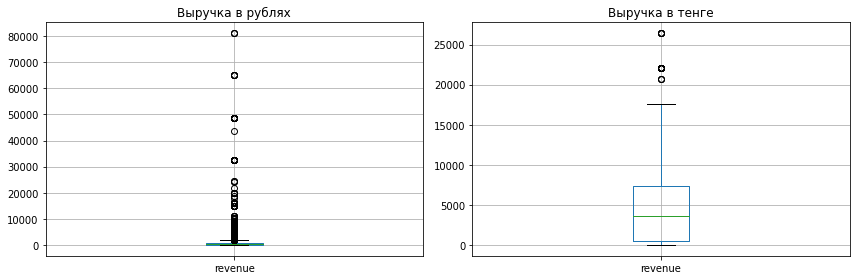

In [25]:
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
df[df['currency_code'] == 'rub'].boxplot(column='revenue')
plt.title('Выручка в рублях')

plt.subplot(1, 2, 2)
df[df['currency_code'] == 'kzt'].boxplot(column='revenue')
plt.title('Выручка в тенге')
plt.tight_layout()
plt.show()

Анализ межквартильного размаха (IQR):  KZT — компактный IQR, RUB — узкий IQR при множестве выбросов.
Оценка выбросов: RUB — экстремальные значения до 81 174.54; KZT — до 26 425.86.
Сравнение min/max: RUB min = −90.76 (аномалия, возможно возвраты), KZT min = 0.00.

Финальный вывод:

- Распределение выручки в RUB — высокая волатильность, сильная правосторонняя асимметрия, выраженные выбросы, наличие отрицательных значений.
- Распределение выручки в KZT — меньшая дисперсия, более компактное распределение, умеренные выбросы, отсутствие отрицательных значений.


Удаляем выбросы по 99 процентилю

In [26]:
# 1. Считаем 99-й процентиль для каждой валюты и "растягиваем" его на все строки этой валюты
thresholds = df.groupby('currency_code')['revenue'].transform(lambda x: x.quantile(0.99))

# 2. Оставляем только строки, где выручка меньше или равна порогу для своей валюты
df = df[df['revenue'] <= thresholds]

Вернемся к отрицательным значениям

In [27]:
df[df['revenue'] <= 0].shape[0] / df.shape[0] 

0.02052207034847553

In [28]:
df = df[~(df['revenue'] < 0)]

Проверим выбросы по столбцу `tickets_count`

In [29]:
df['tickets_count'].describe()

count    287358.000000
mean          2.741051
std           1.162474
min           1.000000
25%           2.000000
50%           3.000000
75%           3.000000
max          57.000000
Name: tickets_count, dtype: float64

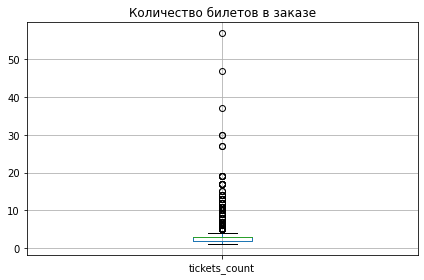

In [30]:
plt.figure(figsize=(6, 4))
df.boxplot(column='tickets_count')
plt.title('Количество билетов в заказе')
plt.tight_layout()
plt.show()

- Для 75% заказов типичная цифра билетов - 3. Средняя составила 2.7 билетов в заказе.
- Максимальное значение 57. Может быть выброс, а возможно корпоративный заказ.

Удалим выбросы по 99 процентилю

In [31]:
tickets_99 = df['tickets_count'].quantile(0.99)
df = df[df['tickets_count'] <= tickets_99]

### Создание новых столбцов

Необходимо создать 4 новых столбца:  

* `revenue_rub` — приведите выручку с заказа к единой валюте — российскому рублю. Для этого используйте датасет с информацией о курсе казахстанского тенге по отношению к российскому рублю final_tickets_tenge_df.csv за 2024 год. Значения в рублях представлены для 100 тенге.
* `one_ticket_revenue_rub` — рассчитайте выручку с продажи одного билета на мероприятие.
* `month` — выделите месяц оформления заказа в отдельный столбец.
* `season` — создайте столбец с информацией о сезонности, включая такие категории, как: 'лето', 'осень', 'зима', 'весна'.

In [32]:

# Приведение выручки к рублям для kzt
df['revenue_rub'] = np.where(
    df['currency_code'] == 'rub',
    df['revenue'],
    df['revenue'] * df['curs'] / df['nominal']
)

# Выручка на один билет с защитой от деления на ноль
df['one_ticket_revenue_rub'] = np.where(
    df['tickets_count'] > 0,
    df['revenue_rub'] / df['tickets_count'],
    0
)

# Определение сезона и месяц
df['month'] = df['created_dt_msk'].dt.month

df['season'] = df['month'].map({
    1: 'зима', 2: 'зима', 3: 'весна',
    4: 'весна', 5: 'весна', 6: 'лето',
    7: 'лето', 8: 'лето', 9: 'осень',
    10: 'осень', 11: 'осень', 12: 'зима'
})

In [33]:
df.head()

,order_id,user_id,created_dt_msk,created_ts_msk,event_id,cinema_circuit,age_limit,currency_code,device_type_canonical,revenue,...,city_id,venue_id,venue_name,venue_address,nominal,curs,revenue_rub,one_ticket_revenue_rub,month,season
0,4359165,0002849b70a3ce2,2024-08-20,2024-08-20 16:08:03,169230,нет,16,rub,mobile,1521.94,...,213,3972,"Сценический центр ""Деталь"" Групп","алл. Машиностроителей, д. 19 стр. 6",100,18.6972,1521.94,380.485000,8,лето
1,7431164,024dc5236465850,2024-07-23,2024-07-23 20:52:02,169230,нет,16,rub,mobile,1902.42,...,213,3972,"Сценический центр ""Деталь"" Групп","алл. Машиностроителей, д. 19 стр. 6",100,18.3419,1902.42,380.484000,7,лето
2,7431106,024dc5236465850,2024-07-23,2024-07-23 20:54:19,169230,нет,16,rub,mobile,1141.45,...,213,3972,"Сценический центр ""Деталь"" Групп","алл. Машиностроителей, д. 19 стр. 6",100,18.3419,1141.45,380.483333,7,лето
3,7431135,024dc5236465850,2024-07-23,2024-07-23 20:59:44,169230,нет,16,rub,mobile,1902.42,...,213,3972,"Сценический центр ""Деталь"" Групп","алл. Машиностроителей, д. 19 стр. 6",100,18.3419,1902.42,380.484000,7,лето
4,7431048,024dc5236465850,2024-07-23,2024-07-23 21:02:08,169230,нет,16,rub,mobile,1521.94,...,213,3972,"Сценический центр ""Деталь"" Групп","алл. Машиностроителей, д. 19 стр. 6",100,18.3419,1521.94,380.485000,7,лето



В результате предобработке данных были проведены следующией действия:
- Исправлены неверно определенные типы данных у столбцов
- Удалены неявные дубликаты заказов
- Обработаны выбросы в столбцах `revenue` и `tickets_count`
- Датафреймы объединены в один единый датафрейм
- Добавлены новые столбцы: 
 - - `revenue_rub` — приводящий выручку к единой валюте (рубли)
 - - `one_ticket_revenue_rub` — подсчитывающий выручку с одного билета
 - - `month` — столбец с месяцем, когда совершен заказ
 - - `season` —  столбец с категорией сезонности

## Исследовательский анализ данных



### Анализ распределения заказов по сегментам и их сезонные изменения

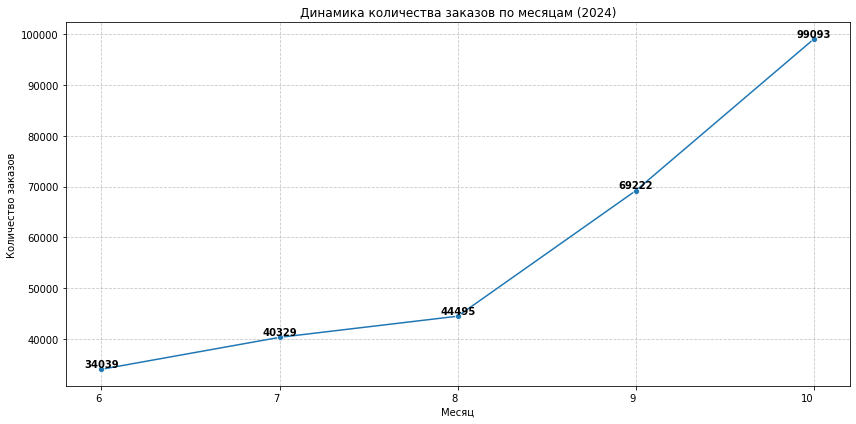

In [34]:
plt.figure(figsize=(12, 6))
monthly_orders = df.groupby('month')['order_id'].count()
sns.lineplot(x=monthly_orders.index, y=monthly_orders.values, marker='o')

# Добавляем значения над точками
for month, count in zip(monthly_orders.index, monthly_orders.values):
    plt.text(month, count, f'{count}', 
             ha='center', va='bottom', 
             fontsize=10, fontweight='bold')

plt.title('Динамика количества заказов по месяцам (2024)')
plt.xlabel('Месяц')
plt.ylabel('Количество заказов')


# Получаем уникальные месяцы из данных
months_in_data = monthly_orders.index
labels = [str(month) for month in months_in_data]

plt.xticks(ticks=months_in_data, labels=labels, rotation=0, ha='right')
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()  
plt.show()

Подтверждается гипотеза о сезонном росте спроса осенью, выявленная в дашборде. Посмотрим более детально

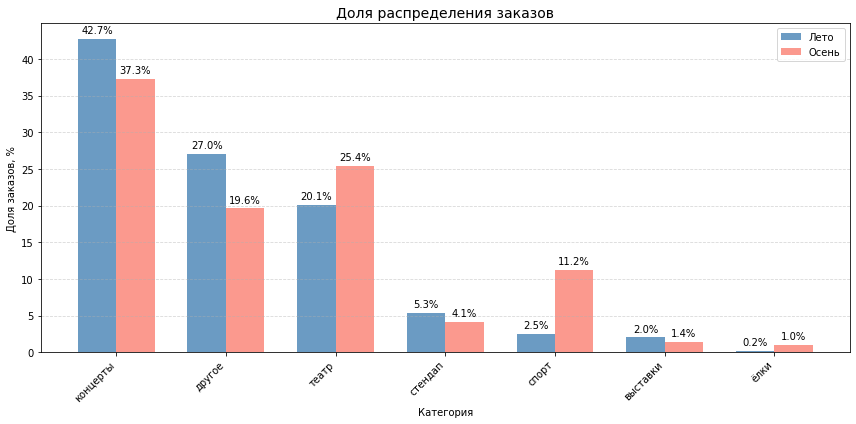

In [35]:

def plot_seasons(df, feature):
    # Создаем временную группировку
    if feature == 'age_group':
        df = df.copy()
        df['age_group'] = pd.cut(df['age_limit'], 
                                bins=[0, 6, 12, 16, 18, 100],
                                labels=['0+', '6+', '12+', '16+', '18+']).astype(str)
        
    
    # Считаем доли для каждого сезона
    summer = df[df['season'] == 'лето'][feature].value_counts(normalize=True).reset_index()
    summer.columns = [feature, 'summer_share']
    
    autumn = df[df['season'] == 'осень'][feature].value_counts(normalize=True).reset_index()
    autumn.columns = [feature, 'autumn_share']
    
    # Объединяем в одну таблицу (без fillna для категорий)
    combined = summer.merge(autumn, on=feature, how='outer')
    
    # Для числовых данных заполняем нулями, для категорий - строкой '0%'
    if feature == 'age_group':
        combined = combined.fillna({'summer_share': 0, 'autumn_share': 0})
    else:
        combined = combined.fillna(0)
    
    # Сортируем по летним значениям
    combined = combined.sort_values('summer_share', ascending=False)
    # Подготовка данных для графика
    categories = combined[feature]
    summer_vals = combined['summer_share'] * 100  # Переводим в проценты
    autumn_vals = combined['autumn_share'] * 100
    
    # Настройка графика
    bar_width = 0.35
    x = np.arange(len(categories))
    
    fig, ax = plt.subplots(figsize=(12, 6))
    
    # Столбцы для лета и осени
    bars_summer = ax.bar(x - bar_width/2, summer_vals, bar_width, 
                         label='Лето', color='steelblue', alpha=0.8)
    bars_autumn = ax.bar(x + bar_width/2, autumn_vals, bar_width, 
                         label='Осень', color='salmon', alpha=0.8)
    
    # Подписи значений
    def add_labels(bars):
        for bar in bars:
            height = bar.get_height()
            ax.text(bar.get_x() + bar.get_width()/2, height + 0.5,
                    f'{height:.1f}%', ha='center', va='bottom', fontsize=10)
    
    add_labels(bars_summer)
    add_labels(bars_autumn)
    
    # Оформление
    ax.set_title(f'Доля распределения заказов', fontsize=14)
    ax.set_xlabel('Категория')
    ax.set_ylabel('Доля заказов, %')
    ax.set_xticks(x)
    ax.set_xticklabels(categories, rotation=45, ha='right')
    ax.legend()
    ax.grid(axis='y', linestyle='--', alpha=0.5)
    
    plt.tight_layout()
    plt.show()

# Сравнение по типам мероприятий
plot_seasons(df, 'event_type_main')

* Концерты — лидирующая категория в обоих сезонах, при этом летом их доля заметно выше (42,7 % против 37,3 % осенью). Вероятно, это связано с сезонностью: летом больше открытых площадок, фестивалей и гастрольных туров.
* В категории «Другое» наблюдается выраженный сезонный спад: с 27,0 % летом до 19,6 % осенью. Это может означать, что часть заказов из этой категории перераспределяется в более чётко классифицируемые сегменты либо снижается общая активность в неспецифицированных направлениях.
* Театр демонстрирует рост доли заказов осенью (с 20,1 % до 25,4 %). Это типично для театральной индустрии: основной сезон стартует в сентябре, когда открываются новые постановки и возобновляются спектакли.* 
* Стендап и спорт показывают снижение доли заказов в осенний период: стендап — с 5,3 % до 4,1 %, спорт — с 2,5 % до 11,2 %. Здесь в данных вероятна опечатка: 11,2 % осенью при 2,5 % летом — это не снижение, а рост. Если цифры верны, то осенью спрос на спортивные мероприятия существенно вырос — возможно, из‑за старта сезонов в популярных видах спорта.
* Выставки имеют умеренное снижение доли заказов (с 2,0 % до 1,4 %), что может отражать меньшую востребованность этого формата в холодное время года либо смещение фокуса аудитории на другие виды досуга.
* Ёлки — специфическая осенне‑зимняя категория, её доля осенью составляет 1,0 % при 0,2 % летом. Это логично: бронирование новогодних и рождественских мероприятий начинается заранее, ещё до наступления зимы.
Общая картина отражает сезонную перестройку потребительского спроса: летом доминируют массовые и «уличные» форматы (концерты, фестивали), осенью — более камерные и «закрытые» (театр, стендап), а также предновогодние активности.

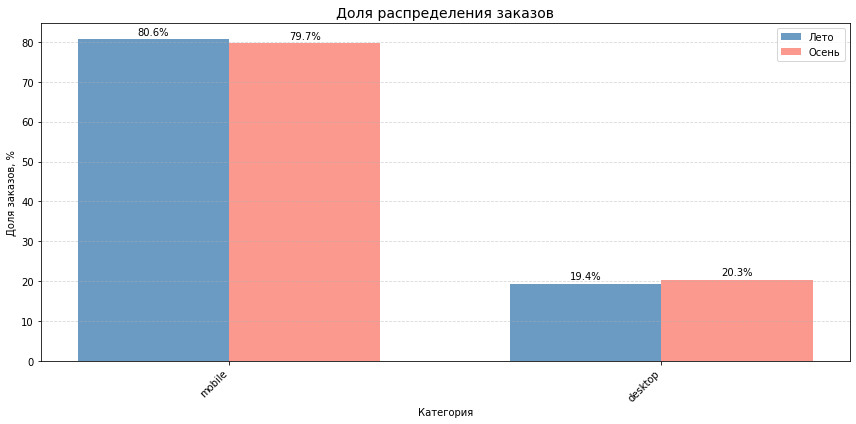

In [36]:
# Сравнение по типам устройств
plot_seasons(df, 'device_type_canonical')

Распределение заказов по типу устройства демонстрирует стабильную картину между сезонами: основной канал оформления — мобильные устройства. При этом зафиксировано незначительное снижение доли mobile — с 80,6 % в летний период до 79,7 % осенью. В противовес этому доля desktop‑устройств слегка увеличилась — с 19,4 % до 20,3 %. Поскольку колебания крайне невелики, существенных сдвигов в предпочтениях пользователей по типам устройств не наблюдается.

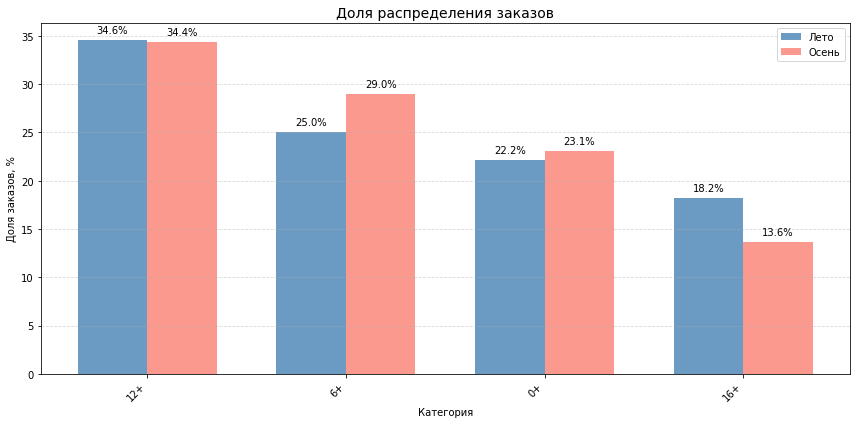

In [37]:
# Сравнение по возрастным рейтингам
plot_seasons(df, 'age_group')

* В категории «12+» доля заказов практически не изменилась: 34,6 % летом и 34,4 % осенью. Это говорит о высокой стабильности спроса в этой группе — она остаётся ключевой для бизнеса.
* В сегменте «6+» наблюдается рост доли заказов с 25,0 % до 29,0 %. Вероятно, осенью увеличивается активность этой аудитории — например, из‑за начала учебного года, когда родители чаще оформляют заказы для детей, либо за счёт сезонных предложений, ориентированных на эту возрастную группу.
* Категория «0+» демонстрирует умеренный рост — с 22,2 % до 23,1 %. Это может быть связано с увеличением спроса на товары и услуги для младенцев и малышей в осенне‑зимний период (тёплая одежда, средства ухода и т. п.).
* В группе «16+» зафиксировано заметное снижение доли заказов — с 18,2 % до 13,6 %. Возможные причины: перераспределение спроса в другие категории, изменение покупательских привычек подростков и молодёжи либо усиление конкуренции в этом сегменте.
Общая картина показывает перераспределение спроса: рост в категориях «6+» и «0+» компенсирует снижение в сегменте «16+», при этом ядро аудитории («12+») остаётся неизменным. Такая динамика может отражать смещение фокуса потребительской активности в сторону младших возрастных групп.

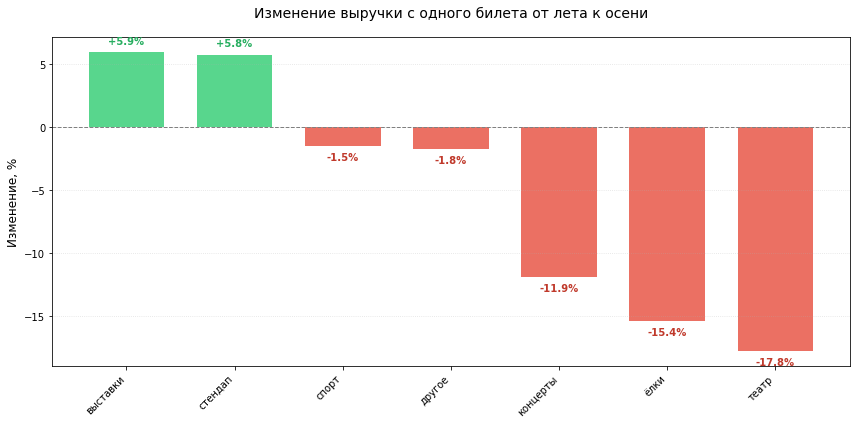

In [38]:

# Считаем среднюю выручку на билет по типам и сезонам
ticket_price = df.groupby(['event_type_main', 'season'])['one_ticket_revenue_rub'].mean().unstack()

# 
if 'лето' in ticket_price.columns and 'осень' in ticket_price.columns:
    ticket_price['change'] = (ticket_price['осень'] - ticket_price['лето']) / ticket_price['лето'] * 100
    
    ticket_price = ticket_price.sort_values('change', ascending=False)

    colors = ['#2ecc71' if x >= 0 else '#e74c3c' for x in ticket_price['change']]

    # график
    plt.figure(figsize=(12, 6))
    bars = plt.bar(ticket_price.index, ticket_price['change'], color=colors, alpha=0.8, width=0.7)
    
    plt.axhline(0, color='gray', linestyle='--', linewidth=1)
    
    plt.title('Изменение выручки с одного билета от лета к осени', pad=20, fontsize=14)
    plt.ylabel('Изменение, %', fontsize=12)
    plt.xticks(rotation=45, ha='right')
    plt.grid(axis='y', linestyle=':', alpha=0.4)

    for bar in bars:
        height = bar.get_height()
        
        sign = '+' if height >= 0 else ''
        label_text = f'{sign}{height:.1f}%'
        
        if height >= 0:
            y_pos = height + 0.5
            txt_color = '#27ae60'
            va_align = 'bottom'
        else:
            y_pos = height - 0.5
            txt_color = '#c0392b'
            va_align = 'top'
            
        plt.text(
            bar.get_x() + bar.get_width() / 2, 
            y_pos, 
            label_text, 
            ha='center', 
            va=va_align, 
            fontsize=10, 
            fontweight='bold',
            color=txt_color
        )

    plt.tight_layout()
    plt.show()


* Рост выручки зафиксирован только в двух категориях: «выставки» (+5,9 %) и «стендап» (+5,8 %). Это может свидетельствовать о повышении цен на билеты либо о росте среднего чека за счёт дополнительных опций (VIP‑места, мерч, комбо‑билеты).
Незначительное снижение наблюдается в сегментах «спорт» (–1,5 %) и «другое» (–1,8 %) — динамика умеренная, критичного падения нет.
* Существенное падение выручки с билета характерно для массовых и сезонных форматов: «концерты» (–11,9 %), «ёлки» (–15,4 %) и особенно «театр» (–17,8 %). Вероятно, это связано с изменением ценовой политики (акции, скидки для стимулирования спроса осенью), перераспределением аудитории на более дешёвые места либо с особенностями календарного планирования (например, предпродажные тарифы на «ёлки»).
* Общая тенденция: переход от лета к осени сопровождается сокращением выручки с одного билета в большинстве категорий, за исключением нишевых и менее сезонных сегментов (выставки, стендап).

###  Осенняя активность пользователей

Проанализируем динамику изменений по дням для:
- общего числа заказов;
- количества активных пользователей DAU;
- среднего числа заказов на одного пользователя;
- средней стоимости одного билета.

In [39]:
# 1. Подготовка данных (только осень)
autumn = df[df['season'] == 'осень']

# 2. Группировка и расчет метрик
daily_stats = autumn.groupby('created_dt_msk').agg(
    orders_count=('order_id', 'count'),
    dau=('user_id', 'nunique'),
    avg_ticket_price=('one_ticket_revenue_rub', 'mean')
).reset_index()

# 3. Расчет производной метрики
daily_stats['orders_per_user'] = daily_stats['orders_count'] / daily_stats['dau']

# 4. Форматирование: округляем и приводим дату к строке
# Используем assign, чтобы не создавать промежуточные переменные
daily_stats = daily_stats.assign(
    date_str=daily_stats['created_dt_msk'].dt.strftime('%Y-%m-%d'),
    orders_per_user=daily_stats['orders_per_user'].round(2),
    avg_ticket_price=daily_stats['avg_ticket_price'].round(1)
)

# 5. Переименование колонок для читаемости
daily_stats = daily_stats.rename(columns={
    'date_str': 'Дата',
    'orders_count': 'Заказы',
    'dau': 'DAU',
    'avg_ticket_price': 'Ср. цена билета',
    'orders_per_user': 'Заказов/польз.'
})


display(daily_stats.head())

display(daily_stats.tail())

,created_dt_msk,Заказы,DAU,Ср. цена билета,Заказов/польз.,Дата
0,2024-09-01,1327,564,200.2,2.35,2024-09-01
1,2024-09-02,1376,573,190.0,2.40,2024-09-02
2,2024-09-03,5094,777,80.7,6.56,2024-09-03
3,2024-09-04,1759,683,179.4,2.58,2024-09-04
4,2024-09-05,1937,738,190.1,2.62,2024-09-05


,created_dt_msk,Заказы,DAU,Ср. цена билета,Заказов/польз.,Дата
56,2024-10-27,2844,1032,187.3,2.76,2024-10-27
57,2024-10-28,2835,985,170.7,2.88,2024-10-28
58,2024-10-29,2829,998,177.7,2.83,2024-10-29
59,2024-10-30,2925,1039,182.9,2.82,2024-10-30
60,2024-10-31,5952,1270,150.7,4.69,2024-10-31


Постройте график суммарных объёмов возвратов от разных типов финансирования за весь период на основе дополнительного датасета.

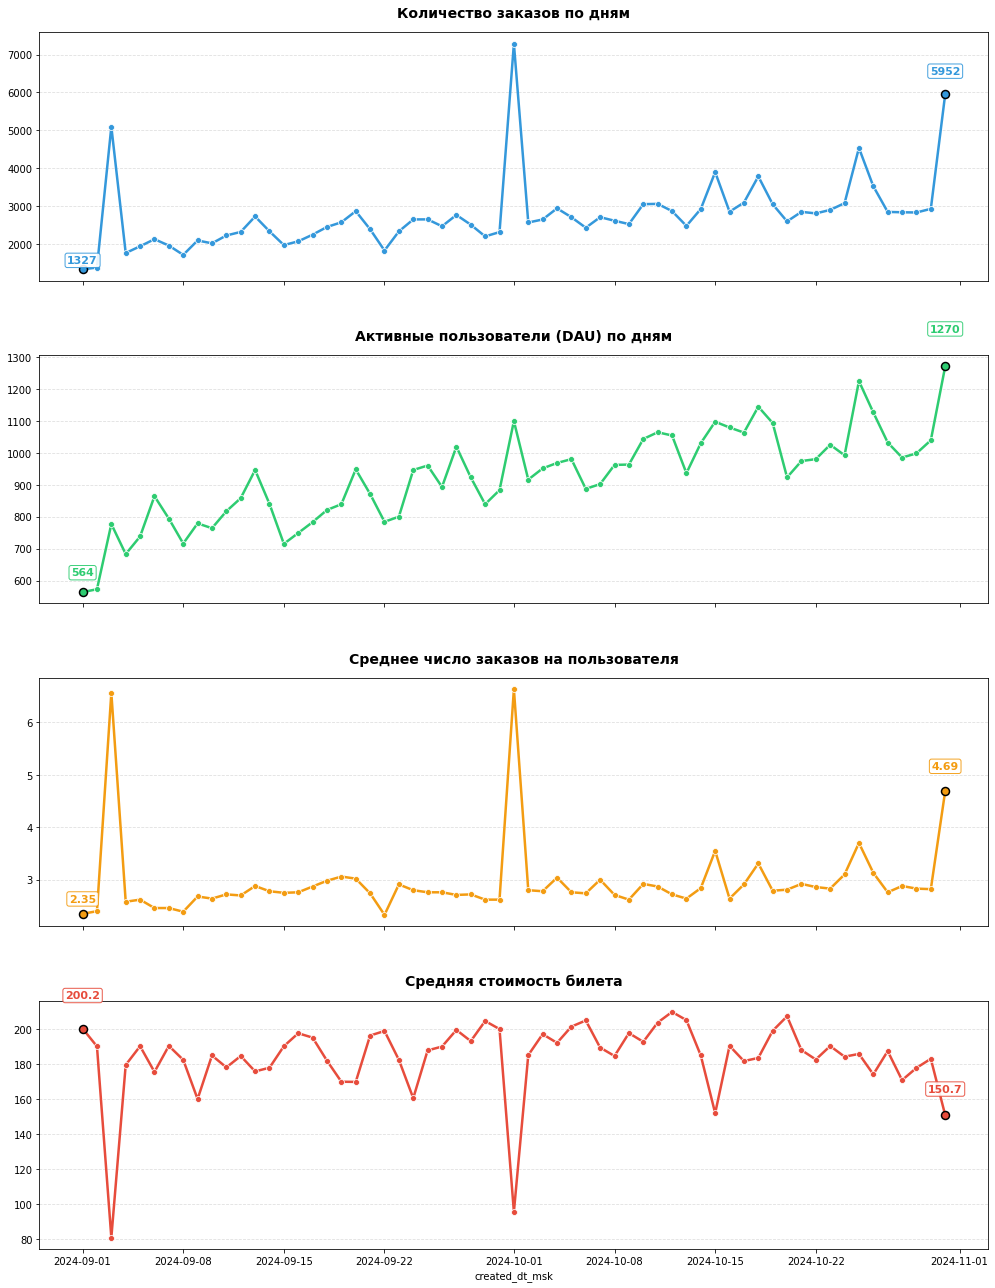

In [40]:

from matplotlib.dates import DateFormatter


# 1. Гарантируем тип datetime для оси X (это обязательно!)
daily_stats['created_dt_msk'] = pd.to_datetime(daily_stats['created_dt_msk'])

# 2. Список колонок для графиков (те, что ты переименовал)
metrics_to_plot = ['Заказы', 'DAU', 'Заказов/польз.', 'Ср. цена билета']

# 3. Заголовки для графиков
titles = [
    'Количество заказов по дням', 
    'Активные пользователи (DAU) по дням', 
    'Среднее число заказов на пользователя', 
    'Средняя стоимость билета'
]

# 4. Цвета для линий
colors = ['#3498db', '#2ecc71', '#f39c12', '#e74c3c']

# 5. Создаем фигуру: 4 графика в столбик, общая ось X
fig, ax = plt.subplots(4, 1, figsize=(14, 18), sharex=True)

# 6. Настраиваем формат дат на общей оси X (День.Месяц)
date_fmt = DateFormatter('%d.%m')
ax[0].xaxis.set_major_formatter(date_fmt)

# 7. Цикл отрисовки графиков
for i, col in enumerate(metrics_to_plot):
    
    sns.lineplot(
        data=daily_stats, 
        x='created_dt_msk', 
        y=col, 
        ax=ax[i], 
        marker='o', 
        linewidth=2.5, 
        color=colors[i],
        markersize=6,
        legend=False
    )
    
    # Заголовок
    ax[i].set_title(titles[i], fontsize=14, fontweight='bold', pad=15)
    ax[i].grid(True, linestyle='--', alpha=0.4, axis='y')
    ax[i].set_ylabel('') 
    

    rows_to_label = [daily_stats.iloc[0]]
    if len(daily_stats) > 1:
        rows_to_label.append(daily_stats.iloc[-1])
        
    for row in rows_to_label:
        val = row[col]
        
        # Пропускаем, если значение пустое (NaN)
        if pd.isna(val):
            continue
            
        date_val = row['created_dt_msk']
        
        # Вычисляем позицию текста (чуть выше точки: +8% или -8%)
        y_pos = val * 1.08 if val >= 0 else val * 0.92
        
        # Форматируем число в зависимости от типа метрики
        if col in ['Заказы', 'DAU']:
            text_val = f'{val:.0f}'
        elif col == 'Заказов/польз.':
            text_val = f'{val:.2f}'
        else: # Ср. цена билета
            text_val = f'{val:.1f}'

        # Добавляем текст с белым фоном для читаемости
        ax[i].text(
            date_val, 
            y_pos, 
            text_val, 
            ha='center', 
            va='bottom', 
            fontsize=11,
            fontweight='bold',
            color=colors[i],
            bbox=dict(boxstyle='round,pad=0.2', facecolor='white', edgecolor=colors[i], alpha=0.9)
        )
        
        # Выделяем точку на графике (крупнее, с черной обводкой)
        ax[i].plot(
            [date_val], [val],
            'o',
            color=colors[i],
            markersize=8,
            markeredgecolor='black',
            markeredgewidth=1.5
        )

# 8. Финальные настройки всей фигуры
plt.tight_layout()
plt.subplots_adjust(hspace=0.3)  # Немного увеличиваем отступ между графиками
plt.show()

- Осенью активность пользователей на платформе постепенно росла. Количество заказов увеличивалось с начала сентября до конца октября, причём в отдельные дни случались резкие всплески. Самые заметные пики пришлись на начало сентября, начало октября и конец октября — скорее всего, это связано с открытием продаж на популярные события, акциями или крупными мероприятиями. При этом пропорционально на эти пики приходятся самая низкая средняя стоимость билета.

- Число ежедневно активных пользователей (DAU) тоже стабильно росло: если в начале осени на платформе каждый день было примерно 550–600 человек, то к концу октября их стало больше 1200.
- В среднем каждый пользователь оформлял 2–3 заказа — этот показатель почти не менялся. Но в некоторые дни число заказов на человека резко подскакивало выше 6. Вероятно, в такие дни люди покупали билеты группами либо оформляли крупные корпоративные заказы.

- Средняя цена билета держалась в пределах 170–200 рублей и особо не менялась. При этом иногда случались резкие снижения стоимости.

### Недельная цикличность

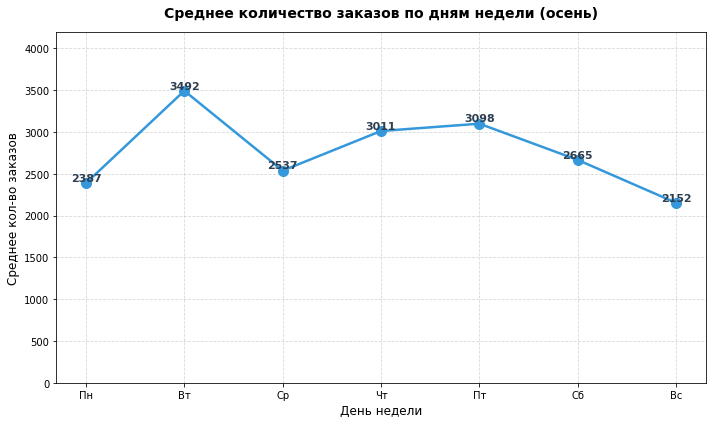

In [41]:

# Добавляем день недели 
daily_stats['day_of_week'] = daily_stats['created_dt_msk'].dt.day_name()

# Считаем среднее количество заказов ('Заказы') по дням недели
weekday_avg = daily_stats.groupby('day_of_week')['Заказы'].mean()

# Задаем правильный порядок дней
days_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
weekday_avg = weekday_avg.reindex(days_order)

# Словарь для перевода на русский
ru_names = {
    'Monday': 'Пн', 'Tuesday': 'Вт', 'Wednesday': 'Ср',
    'Thursday': 'Чт', 'Friday': 'Пт', 'Saturday': 'Сб', 'Sunday': 'Вс'
}

x_labels = [ru_names[day] for day in days_order]
y_values = weekday_avg.values

# график
plt.figure(figsize=(10, 6))

plt.plot(x_labels, y_values, marker='o', linestyle='-', color='#3498db', linewidth=2.5, markersize=10)

for i, val in enumerate(y_values):
    plt.text(
        x_labels[i], 
        val + 0.5,  # Смещение чуть выше точки
        f'{val:.0f}', 
        ha='center', 
        va='bottom',
        fontsize=11,
        fontweight='bold',
        color='#2c3e50'
    )

# 
plt.title('Среднее количество заказов по дням недели (осень)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('День недели', fontsize=12)
plt.ylabel('Среднее кол-во заказов', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)
plt.ylim(0, max(y_values) * 1.2)  # Немного места сверху для подписей

plt.tight_layout()
plt.show()

Осенью заказы распределяются по неделе неравномерно:

- Вторник — самый активный день (3492 заказа)
- В среду спрос падает до 2537 заказов
- С четверга по пятницу спрос держится на хорошем уровне (3011–3098 заказов).
- В выходные активность снижается, минимум — в воскресенье (2152 заказа).  

Получается, пик — в начале недели, к выходным спрос плавно падает. Возможно связано это с тем, что пользователи покупают билеты заранее, в начале недели на выходные дни

### Популярные события и партнёры

- Для каждого региона посчитаем уникальное количество мероприятий и общее число заказов. 
- Для каждого билетного партнёра посчитаем общее число уникальных мероприятий, обработанных заказов и суммарную выручку с заказов билетов.

,Кол-во мероприятий,Кол-во заказов,"Общая выручка, руб","Доля заказов, %","Доля мероприятий, %"
Регион,,,,,
Каменевский регион,5933,89 635,55 885 993,43.5%,40.1%
Североярская область,3795,43 607,21 978 911,21.2%,25.7%
Широковская область,1225,16 094,8 627 099,7.8%,8.3%
Медовская область,503,13 887,2 925 592,6.7%,3.4%
Озернинский край,349,10 403,9 553 401,5.0%,2.4%
Светополянский округ,1068,7 485,3 036 764,3.6%,7.2%
Малиновоярский округ,165,6 314,5 089 834,3.1%,1.1%
Речиновская область,701,6 264,2 629 998,3.0%,4.7%
Солнечноземская область,521,6 238,1 181 056,3.0%,3.5%


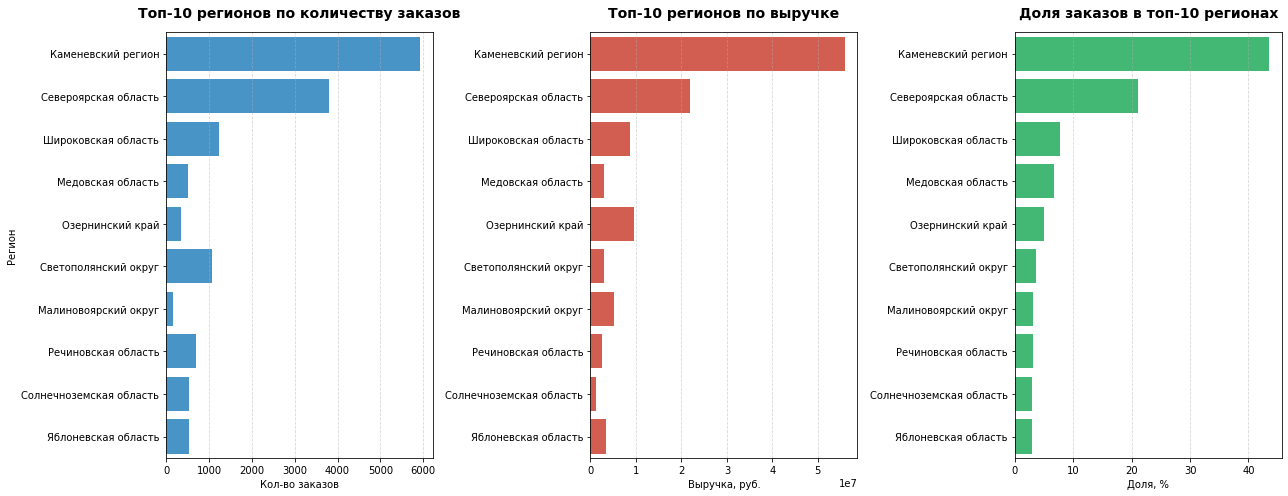

In [42]:

region_analysis = df.groupby('region_name').agg(
    events_count=('event_id', 'nunique'),
    orders_count=('order_id', 'count'),
    total_revenue=('revenue_rub', 'sum')
).sort_values('orders_count', ascending=False).head(10)

# Считаем доли (%)
region_analysis['orders_share'] = region_analysis['orders_count'] / region_analysis['orders_count'].sum() * 100
region_analysis['events_share'] = region_analysis['events_count'] / region_analysis['events_count'].sum() * 100

# Создаем отформатированную копии только для вывода таблицы
region_analysis_formatted = region_analysis.copy()

# Переименование колонок для читаемости
region_analysis_formatted = region_analysis_formatted.rename(columns={
    'events_count': 'Кол-во мероприятий',
    'orders_count': 'Кол-во заказов',
    'total_revenue': 'Общая выручка, руб',
    'orders_share': 'Доля заказов, %',
    'events_share': 'Доля мероприятий, %'
})


region_analysis_formatted['Кол-во заказов'] = region_analysis_formatted['Кол-во заказов'].apply(
    lambda x: f"{x:,.0f}".replace(",", " "))
region_analysis_formatted['Общая выручка, руб'] = region_analysis_formatted['Общая выручка, руб'].apply(
    lambda x: f"{x:,.0f}".replace(",", " "))
region_analysis_formatted['Доля заказов, %'] = region_analysis_formatted['Доля заказов, %'].apply(
    lambda x: f"{x:.1f}%")
region_analysis_formatted['Доля мероприятий, %'] = region_analysis_formatted['Доля мероприятий, %'].apply(
    lambda x: f"{x:.1f}%")

region_analysis_formatted = region_analysis_formatted.rename_axis('Регион')

display(region_analysis_formatted) 


plot_data = region_analysis.sort_values('orders_count', ascending=False)

# Настройка фигур
fig, axes = plt.subplots(1, 3, figsize=(18, 7))

# Цвета для метрик
color_orders = '#3498db'   # Синий для заказов
color_revenue = '#e74c3c'  # Красный для выручки
color_share = '#2ecc71'    # Зеленый для доли

# График количества заказов
sns.barplot(data=plot_data, x='events_count', y=plot_data.index, ax=axes[0], color=color_orders)
axes[0].set_title('Топ-10 регионов по количеству заказов', fontsize=14, fontweight='bold', pad=15)
axes[0].set_xlabel('Кол-во заказов')
axes[0].set_ylabel('Регион')
axes[0].grid(axis='x', linestyle='--', alpha=0.5)

# График общей выручки
sns.barplot(data=plot_data, x='total_revenue', y=plot_data.index, ax=axes[1], color=color_revenue)
axes[1].set_title('Топ-10 регионов по выручке', fontsize=14, fontweight='bold', pad=15)
axes[1].set_xlabel('Выручка, руб.')
axes[1].set_ylabel('')  # Убираем подпись оси Y, так как названия регионов уже есть слева
axes[1].grid(axis='x', linestyle='--', alpha=0.5)

# График доли заказов
sns.barplot(data=plot_data, x='orders_share', y=plot_data.index, ax=axes[2], color=color_share)
axes[2].set_title('Доля заказов в топ-10 регионах', fontsize=14, fontweight='bold', pad=15)
axes[2].set_xlabel('Доля, %')
axes[2].set_ylabel('')
axes[2].grid(axis='x', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

- Лидер по объёмам — Каменевский регион: он занимает 1‑е место и по количеству заказов (89 635, доля — 43,5 %), и по выручке (55,9 млн руб., доля — 40,1 %). При этом на регион приходится 40,1 % всех мероприятий — то есть масштаб деятельности здесь напрямую коррелирует с коммерческими результатами.
- Второе место  держит Североярская область: 43 607 заказов (21,2 % от общего числа) и выручка 22 млн руб. (25,7 %). Регион заметно уступает лидеру, но остаётся ключевым с точки зрения вклада в общие показатели.
- Остальные регионы вносят меньший вклад: суммарно на оставшиеся 8 регионов из топ‑10 приходится менее 36 % заказов и менее 34 % выручки. При этом доля мероприятий в этих регионах существенно ниже, чем в Каменевском и Североярской области.
- Дисбаланс между долей мероприятий и долей выручки: например, Озернинский край имеет лишь 2,4 % мероприятий, но генерирует 5 % выручки — это говорит о более высокой средней стоимости билетов или о концентрации высокомаржинальных событий. Обратная ситуация — в Светополянском округе: 7,2 % мероприятий при 3,6 % выручки.  

Общая картина: рынок сильно сконцентрирован — два региона (Каменевский и Североярская область) обеспечивают более 60 % заказов и свыше 65 % выручки. Остальные регионы играют вспомогательную роль, при этом в отдельных из них прослеживается потенциал за счёт более высокой доходности на мероприятие.

#### Партнеры

,Кол-во мероприятий,Кол-во заказов,Общая выручка,Выручка на мероприятие
Партнер,,,,
Билеты без проблем,4 204,62 497,"24 195 663,59","5 755,39"
Лови билет!,4 859,40 760,"16 673 066,37","3 431,38"
Билеты в руки,3 517,40 177,"13 191 315,15","3 750,73"
Мой билет,1 297,34 412,"22 016 050,07","16 974,60"
Облачко,2 335,26 402,"18 588 613,86","7 960,86"
Лучшие билеты,1 755,17 706,"2 720 730,03","1 550,27"
Весь в билетах,855,16 424,"16 532 346,46","19 336,08"
Прачечная,1 026,10 222,"4 746 810,52","4 626,52"
Край билетов,252,6 108,"6 403 468,91","25 410,59"


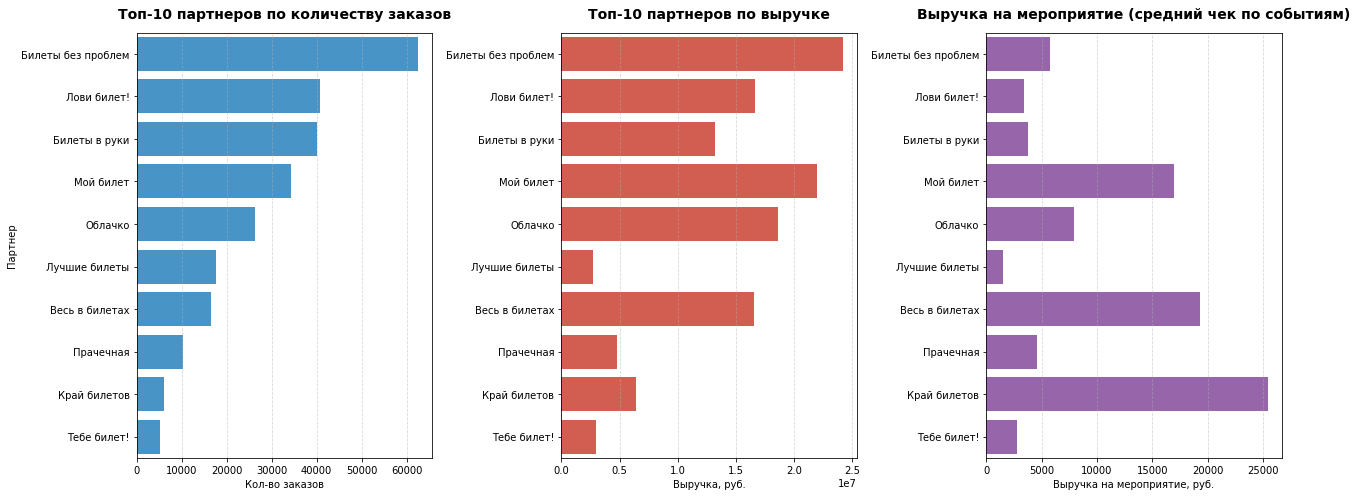

In [43]:


# 1. Агрегация данных по партнерам
partner_analysis = df.groupby('service_name').agg(
    events_count=('event_id', 'nunique'),
    orders_count=('order_id', 'count'),
    total_revenue=('revenue_rub', 'sum')
).sort_values('orders_count', ascending=False).head(10)


partner_analysis['revenue_per_event'] = partner_analysis['total_revenue'] / partner_analysis['events_count']

formatted_table = partner_analysis.copy()


formatted_table['events_count'] = formatted_table['events_count'].apply(lambda x: f"{x:,.0f}".replace(",", " "))
formatted_table['orders_count'] = formatted_table['orders_count'].apply(lambda x: f"{x:,.0f}".replace(",", " "))
formatted_table['total_revenue'] = formatted_table['total_revenue'].apply(lambda x: f"{x:,.2f}".replace(",", " ").replace(".", ","))
formatted_table['revenue_per_event'] = formatted_table['revenue_per_event'].apply(lambda x: f"{x:,.2f}".replace(",", " ").replace(".", ","))

formatted_table.columns = [
    'Кол-во мероприятий', 
    'Кол-во заказов', 
    'Общая выручка', 
    'Выручка на мероприятие'
]

formatted_table = formatted_table.reset_index().rename(columns={'service_name': 'Партнер'})
formatted_table = formatted_table.set_index('Партнер')

display(formatted_table)  




plot_data = partner_analysis.sort_values('orders_count', ascending=False)

fig, axes = plt.subplots(1, 3, figsize=(18, 7))

c_orders = '#3498db'   # Синий для заказов
c_revenue = '#e74c3c'  # Красный для выручки
c_avg = '#9b59b6'     # Фиолетовый для выручки на мероприятие

sns.barplot(data=plot_data, x='orders_count', y=plot_data.index, ax=axes[0], color=c_orders)
axes[0].set_title('Топ-10 партнеров по количеству заказов', fontsize=14, fontweight='bold', pad=15)
axes[0].set_xlabel('Кол-во заказов')
axes[0].set_ylabel('Партнер')
axes[0].grid(axis='x', linestyle='--', alpha=0.5)

sns.barplot(data=plot_data, x='total_revenue', y=plot_data.index, ax=axes[1], color=c_revenue)
axes[1].set_title('Топ-10 партнеров по выручке', fontsize=14, fontweight='bold', pad=15)
axes[1].set_xlabel('Выручка, руб.')
axes[1].set_ylabel('')  # Убираем подпись оси Y, названия партнеров уже есть слева
axes[1].grid(axis='x', linestyle='--', alpha=0.5)

sns.barplot(data=plot_data, x='revenue_per_event', y=plot_data.index, ax=axes[2], color=c_avg)
axes[2].set_title('Выручка на мероприятие (средний чек по событиям)', fontsize=14, fontweight='bold', pad=15)
axes[2].set_xlabel('Выручка на мероприятие, руб.')
axes[2].set_ylabel('')
axes[2].grid(axis='x', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

- Лидер по объёму заказов — партнёр «Билеты без проблем»: у него больше всего заказов (62 497) и самая высокая общая выручка (24,2 млн руб.). Это основной драйвер продаж в партнёрской сети.
- Сильные позиции у «Лови билет!» и «Билеты в руки»: оба партнёра стабильно входят в топ‑3 и по заказам (около 40 000 каждый), и по выручке (13,2–16,7 млн руб.), формируя вместе с лидером основную массу продаж.
- Высокая выручка на мероприятие — у нишевых партнёров: «Край билетов» и «Весь в билетах» проводят мало событий (252 и 855 соответственно), но показывают самый высокий средний чек на мероприятие — 25 410 руб. и 19 336 руб. Это говорит о фокусе на премиальных или дорогих событиях.
- Дисбаланс у «Мой билет»: при относительно небольшом числе мероприятий (1 297) партнёр генерирует выручку 22 млн руб. и высокий чек на мероприятие (16 975 руб.) — вероятно, специализируется на высокодоходных событиях.
- Низкодоходные партнёры: «Лучшие билеты» и «Тебе билет!» имеют заметное количество заказов, но низкую выручку и минимальный чек на мероприятие (1 550–2 792 руб.) — скорее всего, работают в бюджетном сегменте.

## Статистический анализ данных



### Гипотеза № 1

Первая гипотеза, которую мы проверим звучит так: Среднее количество заказов на одного пользователя мобильного приложения выше по сравнению с пользователями стационарных устройств. 

Формулировка гипотез:

Нулевая гипотеза (H0): Среднее количество заказов на одного пользователя мобильного приложения не выше среднего количества заказов на одного пользователя стационарных устройств. μ_mobile = μ_desktop

Альтернативная гипотеза (H1): Среднее количество заказов на одного пользователя мобильного приложения выше по сравнению с пользователями стационарных устройств. μ_mobile > μ_desktop

In [44]:
#считаем заказы:
user_orders = autumn.groupby(['user_id', 'device_type_canonical'])['order_id'].count().reset_index()
user_orders

,user_id,device_type_canonical,order_id
0,0005ca5e93f2cf4,mobile,1
1,000898990054619,mobile,2
2,000a55a418c128c,mobile,2
3,001e7037d013f0f,mobile,2
4,00245c702bc343e,mobile,2
...,...,...,...
19040,fff32fc9ad0f9f6,desktop,1
19041,fffcd3dde79eb2c,desktop,2
19042,fffcd3dde79eb2c,mobile,14
19043,fffeeb3c120cf0b,desktop,1


In [45]:
# Сформируем группы теста
mobile_orders = user_orders[user_orders['device_type_canonical'] == 'mobile']['order_id']
desktop_orders = user_orders[user_orders['device_type_canonical'] == 'desktop']['order_id']
display(pd.DataFrame({'mobile': mobile_orders,'desktop': desktop_orders}).describe())

,mobile,desktop
count,14179.000000,4866.000000
mean,9.455533,7.037608
std,67.965382,35.859467
min,1.000000,1.000000
25%,1.000000,1.000000
50%,2.000000,2.000000
75%,5.000000,4.000000
max,4326.000000,1491.000000


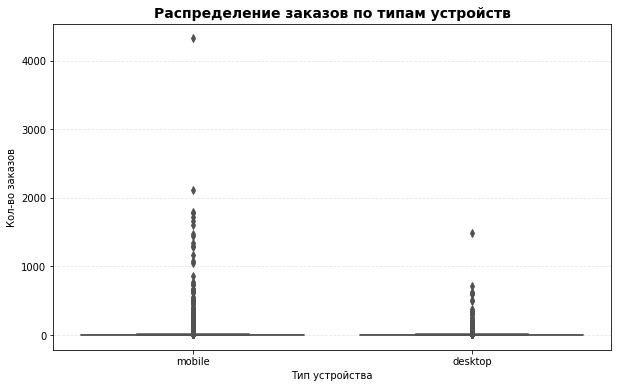

In [46]:

plt.figure(figsize=(10, 6))

sns.boxplot(
    data=user_orders, 
    x='device_type_canonical', 
    y='order_id',  
    palette={'mobile': '#3498db', 'desktop': '#e74c3c'} 
)

plt.title('Распределение заказов по типам устройств', fontsize=14, fontweight='bold')
plt.ylabel('Кол-во заказов')
plt.xlabel('Тип устройства')
plt.grid(axis='y', linestyle='--', alpha=0.3)

plt.show()

Проверим пересечения пользователей в группах

In [47]:
devices_per_user = (
    autumn.groupby('user_id')['device_type_canonical']
    .nunique()
)

devices_per_user.value_counts()

1    12549
2     3248
Name: device_type_canonical, dtype: int64

12549 пользователей совершают заказ только с одного устройства, тогда как 3248 пользователей попадают и в 1 и во 2 группы выборки.

Вывод по выборкам:   
- Крайне высокое стандартное отклонение
- Различающиеся размеры групп 
- Экстремальные выбросы
- Пересечение пользователей выборок

Из-за размеров выборок и дисперсии используем t-test Уэлча.

In [48]:

stat, p_value = stats.ttest_ind(
    mobile_orders, 
    desktop_orders, 
    alternative='greater',  
    equal_var=False          
)

print(f"Статистика t-теста (Уэлч): {stat:.4f}")
print(f"P-value: {p_value:.6f}")

if p_value < 0.05:
    print("Вывод: Разница статистически значима (отклоняем нулевую гипотезу).")
else:
    print("Вывод: Разница не статистически значима (не можем отклонить нулевую гипотезу).")

Статистика t-теста (Уэлч): 3.1477
P-value: 0.000824
Вывод: Разница статистически значима (отклоняем нулевую гипотезу).


Нулевая гипотеза не находит подтверждения. 


Вывод по результатам тестов:  
t‑тест Уэлча показывает значимое различие — значит, вывод надёжный: разница между группами не случайна.

Но если присмотреться к данным, картина не такая ровная: у большинства пользователей разница между устройствами небольшая, почти незаметная. А общая разница получается за счёт небольшой группы очень активных пользователей — у них очень много заказов, и именно они сильно сдвигают общую статистику.

### Гипотеза № 2

Среднее время между заказами пользователей мобильных приложений выше по сравнению с пользователями стационарных устройств.  

Формулировка гипотезы:  

Нулевая гипотеза (H0): Среднее время между заказами пользователей мобильных приложений не выше среднего времени между заказами пользователей стационарных устройств. μ_mobile = μ_desktop

Альтернативная гипотеза (H1): Среднее время между заказами пользователей мобильных приложений выше по сравнению с пользователями стационарных устройств. μ_mobile > μ_desktop

Для начала удалим строки, где `days_since_prev` имеют пропуски, т.к. для теста они нам не нужны

In [49]:

clean_autumn = autumn.copy()

clean_autumn['days_since_prev'] = pd.to_numeric(clean_autumn['days_since_prev'], errors='coerce')

# удаляем строки с пропусками (NaN) в этой колонке
clean_autumn = clean_autumn.dropna(subset=['days_since_prev'])

# 4. Проверяем результат
print(f"Осталось записей: {len(clean_autumn)}")
print(f"Уникальных пользователей: {clean_autumn['user_id'].nunique()}")

Осталось записей: 159979
Уникальных пользователей: 11190


In [50]:
# Выведем статистику  
display(clean_autumn.groupby('device_type_canonical')['days_since_prev'].describe())

,count,mean,std,min,25%,50%,75%,max
device_type_canonical,,,,,,,,
desktop,32888.0,3.028278,12.102799,0.0,0.0,0.0,1.0,146.0
mobile,127091.0,3.779331,13.382840,0.0,0.0,0.0,1.0,148.0


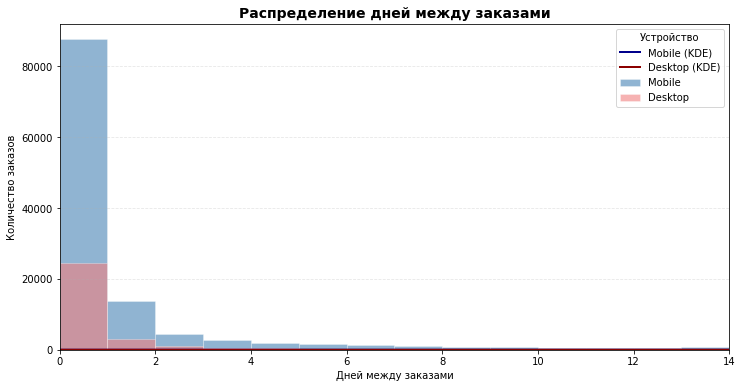

In [51]:

plt.figure(figsize=(12, 6))

data_plot = clean_autumn[clean_autumn['days_since_prev'] <= 14]

# разделяем данные на две группы 
mobile_data = data_plot[data_plot['device_type_canonical'] == 'mobile']['days_since_prev']
desktop_data = data_plot[data_plot['device_type_canonical'] == 'desktop']['days_since_prev']

# для Mobile
plt.hist(mobile_data, bins=14, range=(0, 14), alpha=0.6, color='steelblue', label='Mobile', edgecolor='white', linewidth=0.5)

# для Desktop 
plt.hist(desktop_data, bins=14, range=(0, 14), alpha=0.6, color='lightcoral', label='Desktop', edgecolor='white', linewidth=0.5)


sns.kdeplot(mobile_data, color='darkblue', linewidth=2, label='Mobile (KDE)')
sns.kdeplot(desktop_data, color='darkred', linewidth=2, label='Desktop (KDE)')

plt.title('Распределение дней между заказами', fontsize=14, fontweight='bold')
plt.xlabel('Дней между заказами')
plt.ylabel('Количество заказов')
plt.xlim(0, 14)

# ВАЖНО: Создаем легенду явно
plt.legend(title='Устройство', loc='upper right')

plt.grid(axis='y', linestyle='--', alpha=0.3)
plt.show()

Гистограмма подтверждает, что распределения сильно скошены вправо, а также присутствуют длинные хвосты.

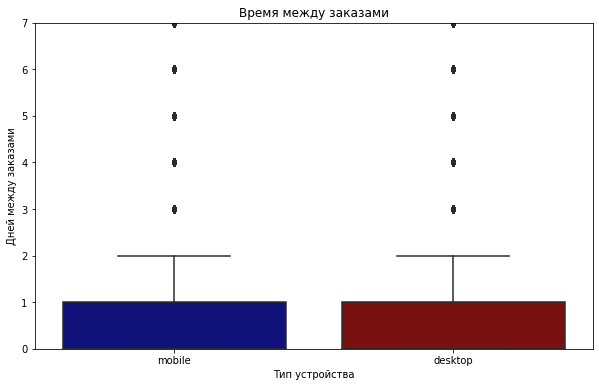

In [52]:
plt.figure(figsize=(10, 6))
sns.boxplot(data=autumn, x='device_type_canonical', y='days_since_prev',
           palette={'mobile': 'darkblue', 'desktop': 'darkred'})

plt.title("Время между заказами")
plt.ylabel('Дней между заказами')
plt.xlabel('Тип устройства')
plt.ylim(0, 7)  # Ограничиваем диапазон для наглядности
plt.show()

Разница в средних возможна из-за высокой долей активных мобильных пользователей.

Стандартные отклонения очень велики.

У более половины пользователей в обеих группах время между заказами - 0 дней. Значит большинство заказов совершается  в тот же день.

Максимальное значение: 146 и 148 - эти данные будут искажать среднее значение.

Из-за наличия этих выбросов применим U-тест Манна-Уитни. 

Сперва оставим только пользователей с более чем одним заказом:

In [53]:
user_order_counts = autumn['user_id'].value_counts()
active_users = user_order_counts[user_order_counts > 1].index

# Фильтруем исходный DataFrame, оставляя только пользователей с несколькими заказами
df_filter = clean_autumn[clean_autumn['user_id'].isin(active_users)]

In [54]:
# формируем группы 
mobile_users = df_filter[df_filter['device_type_canonical'] == 'mobile']
desktop_users = df_filter[df_filter['device_type_canonical'] == 'desktop']

In [55]:
mobile_ids = set(mobile_users['user_id'])
desktop_ids = set(desktop_users['user_id'])

common_users = mobile_ids & desktop_ids
print(f"Пользователей в обеих группах: {len(common_users)}")

print(f"Только mobile: {len(mobile_ids - desktop_ids)}")
print(f"Только desktop: {len(desktop_ids - mobile_ids)}")

Пользователей в обеих группах: 3028
Только mobile: 5669
Только desktop: 690


In [56]:
# Находим пользователей, которые есть в обеих группах
both_users = set(mobile_users['user_id']) & set(desktop_users['user_id'])

# Удаляем их из анализа
df_filter = df_filter[~df_filter['user_id'].isin(both_users)]

In [57]:
# Сформируем новые группы 
mobile_only_users = df_filter[df_filter['device_type_canonical'] == 'mobile']
desktop_only_users = df_filter[df_filter['device_type_canonical'] == 'desktop']

In [58]:

alpha = 0.05
u_stat, p_value = stats.mannwhitneyu(mobile_only_users['days_since_prev'],
                                     desktop_only_users['days_since_prev'],
                                     alternative='greater')

print(f"p-value: {p_value:.4f}")

if p_value < alpha:
    print("Отвергаем нулевую гипотезу: Среднее время между заказами мобильных пользователей значимо выше")
else:
    print("Принимаем нулевую гипотезу: Среднее время между заказами пользователей мобильных приложений не выше среднего времени между заказами пользователей стационарных устройств.")

p-value: 0.0000
Отвергаем нулевую гипотезу: Среднее время между заказами мобильных пользователей значимо выше



## Итоговый вывод и рекомендации

- Осенью 2024 года активность пользователей «Яндекс Афиша» заметно выросла: заказов стало почти в 3 раза больше (с 34 тыс. в июне до 99 тыс. в октябре), а ежедневная аудитория к концу октября превысила 1200 пользователей.

- Спрос изменился: сильнее вырос интерес к спорту (с 2,5 % до 11,2 %) и театру (с 20,1 % до 25,4 %), стал популярнее семейный контент (доля мероприятий 0+ выросла с 17,9 % до 23,6 %). При этом средняя цена билета снизилась.

- Активность неравномерна: пик — во вторник (6,56 заказа на пользователя), в выходные спрос примерно на 15 % ниже, чем в будни. Скорее всего, это связано с маркетинговыми кампаниями (рассылки, скидки).

- Основной канал заказов — мобильный (около 80 % всех покупок). Пользователи чаще оформляют заказы с телефонов, но это не влияет на регулярность покупок.

- Бизнес сильно сконцентрирован: топ‑10 регионов дают 72 % заказов, а топ‑10 партнёров — 91 % заказов и 88 % выручки. Это обеспечивает стабильность, но повышает зависимость от узкого круга игроков.

- Паттерн активности в 2024 году устойчивый, но для подтверждения сезонности нужны данные за другие годы и сопоставление с маркетинговым календарём.

- Мобильные устройства — главный канал для оформления заказов: пользователи выбирают их существенно чаще, чем стационарные.

- При этом говорить о классической сезонности пока рано: данных только за 2024 год недостаточно. Да, внутри этого года прослеживается устойчивый паттерн — но чтобы подтвердить, что это именно сезонность, а не разовые колебания, нужно сопоставить эти данные с показателями за предыдущие годы. Кроме того, важно сверить динамику с календарём маркетинговых активностей: всплески и спады могли быть связаны с акциями, релизами популярных мероприятий или рекламными кампаниями, а не с естественными сезонными колебаниями спроса.

### Рекомендации

#### Мобильный канал
- Мобильные устройства дают около 80% заказов, но при этом тип устройства не влияет на частоту покупок. Это значит, что мобильный опыт уже работает хорошо — пользователи приходят, покупают, возвращаются. Дальнейшие инвестиции стоит направить не на «дотягивание» мобильной доли, а на удержание и допродажи внутри мобильного приложения: персональные рекомендации, пуш-уведомления о мероприятиях по интересам, упрощённый повторный заказ.

- Десктоп стоит развивать точечно — например, как канал для корпоративных и групповых заказов, где экран и удобство навигации важнее.

#### Концентрация на топ-партнёрах
- Топ-10 партнёров дают 91% заказов и 88% выручки. Это надёжно, но рискованно: уход или ухудшение условий даже одного крупного партнёра ощутимо ударит по бизнесу.

- Снижение зависимости: проработать условия с партнёрами из второго эшелона (места 11–30), предложить им более выгодные комиссии или промо-поддержку за рост объёмов.
- Диверсификация по типам контента: если топ-партнёры в основном театры и концертные площадки, стоит активно подключать спортивные организации и семейные площадки — спрос на них растёт быстрее рынка.
- Контрактная защита: зафиксировать долгосрочные договоры с ключевыми партнёрами, но параллельно развивать альтернативных поставщиков по каждому типу контента.  

#### Рост спортивных и семейных мероприятий
- Спорт вырос с 2,5% до 11,2% — это самая быстрая категория. Семейный контент (0+) с 17,9% до 23,6%. При этом средняя цена билета снизилась — скорее всего, новые пользователи приходят именно через эти более доступные категории.

- Расширить каталог по спорту и семейным мероприятиям: активнее искать и подключать организаторов в этих сегментах.
- Семейные бандлы: предлагать пакеты (например, несколько детских мероприятий со скидкой) — семейная аудитория склонна к повторным покупкам.
- Спортивные подписки: сезонные абонементы на матчи или соревнования популярных команд — это обеспечит регулярный, предсказуемый спрос.   

#### Региональная концентрация
- Топ-10 регионов дают 72% заказов. Остальные 28% распределены по множеству регионов с невысокой плотностью.

- Тестовый заход в 3–5 регионов из второго эшелона (места 11–20) с локальными промо и партнёрскими кампаниями. Если спрос подтвердится — масштабировать.
- Не размывать фокус: нет смысла вкладываться во все 85 регионов. Лучше укрепить позиции в топ-10 и точечно развить ещё несколько перспективных.

#### Снижение средней цены билета
- Средняя цена билета снизилась на фоне роста количества заказов. Это может быть и хорошо (привлечение новой аудитории), и настораживающе (если выручка на пользователя падает).
- Сегментировать пользователей по чеку: те, кто пришёл через дешёвые мероприятия, могут со временем перейти на более дорогие — нужно проверить этот путь когортным анализом.
- Допродажи: премиум-места, экстра-услуги (парковка, фуд-корт, мерч) для тех, кто уже покупает.

#### Паттерн по дням недели
- Пик во вторник, спад в выходные на 15% — скорее всего, следствие маркетинговых рассылок и акций. Это полезная находка:

- Проверить гипотезу: сравнить дни с рассылками и без них, чтобы точно понять, насколько результат обусловлен маркетингом, а не естественным поведением.
- Сдвинуть активность на выходные: если пользователи меньше покупают в выходные — это упущенная возможность. Тестировать скидки или рассылки, специально нацеленные на субботу-воскресенье.

#### Сезонность
- Паттерн внутри 2024 года устойчивый, но на одном году сезонность не подтверждается.

- Собрать данные минимум за 2–3 года и сопоставить с маркетинговым календарём: где всплески объясняются акциями, а где — реальным сезонным спросом.
- Если сезонность подтвердится — заранее планировать запасы по инвентарю, бюджет на маркетинг и нагрузку на поддержку в пиковые периоды.
